In [20]:
%matplotlib inline

from glob import glob
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import os

os.environ['PATH'] = '/Library/TeX/texbin:' + os.environ['PATH']

In [21]:
LABELS = {
    'rej.enc'       : 'FLDR',
    'alias.exact'   : 'Walker Alias Sampler',
    'alias.integers_old' : 'Our Integer-Alias Sampler',
    'aldr'          : 'ALDR',
    'alias.rust'    : 'Rust-Alias Sampler',
    'alias.fractions' : 'Fraction-Alias Sampler',
    'alias.integers_gmp' : 'Our Integer-Alias Sampler (GMP)',
    'aldr_gmp' : 'ALDR (GMP)',
    'rej.enc_gmp' : "FLDR (GMP)",
    'alias.rust_gmp' : 'Rust-Alias Sampler (GMP)',
    'alias.fractions_gmp' : 'Fraction-Alias Sampler (GMP)',
    'alias.integers_opt' : 'Our Integer-Alias Sampler (GMP, optimized)',
    'rej.enc_opt' : 'FLDR (GMP, optimized)',
    'aldr_opt' : 'ALDR (GMP, optimized)',
    'alias.rust_opt' : 'Rust-Alias Sampler (GMP, optimized)',
    'alias.fractions_opt' : 'Fraction-Alias Sampler (GMP, optimized)',
    'alias.integers_v2' : 'Our Integer-Alias Sampler (GMP, v2: 64-bit word)'
}

LABELS = {
    'rej.enc'       : 'FLDR',
    'alias.exact'   : 'Walker Alias Sampler',
    'alias.integers_old' : 'Our Integer-Alias Sampler',
    'aldr'          : 'ALDR',
    'alias.rust'    : 'Rust-Alias Sampler',
    'alias.fractions' : 'Fraction-Alias Sampler',
    'alias.integers_gmp' : 'Our Integer-Alias Sampler (GMP)',
    'aldr_gmp' : 'ALDR (GMP)',
    'rej.enc_gmp' : "FLDR (GMP)",
    'alias.rust_gmp' : 'Rust-Alias Sampler (GMP)',
    'alias.fractions_gmp' : 'Fraction-Alias Sampler (GMP)',
    'alias.integers_opt' : 'Our Integer-Alias Sampler (GMP, v1)',
    'rej.enc_opt' : 'FLDR (GMP)',
    'aldr_opt' : 'ALDR (GMP)',
    'alias.rust_opt' : 'Rust-Alias Sampler (GMP)',
    'alias.fractions_opt' : 'Fraction-Alias Sampler (GMP)',
    'alias.integers_v2' : 'Our Integer-Alias Sampler (GMP, v2)'
}

# Une teinte par algorithme : clair = original (GMP), foncé = version optimisée
_tab20 = plt.get_cmap('tab20').colors
COLORS = {}
for k, base in enumerate(['rej.enc', 'aldr', 'alias.rust', 'alias.fractions', 'alias.integers']):
    COLORS[base + '_opt'] = _tab20[2 * k]
    COLORS[base + '_gmp'] = _tab20[2 * k + 1]
COLORS['alias.integers_v2'] = _tab20[18]  # cyan, distinct des cinq autres teintes


In [22]:
def get_entropy(fname):
    with open(fname, 'r') as f:
        return float(f.readlines()[-1])
    
def parse_decimal(value):
    if hasattr(value, "decode"):
        value = value.decode()
    return float(value.replace(",", "."))

In [23]:
# Penser à changer le n et le Z en fonction du dossier que l'on veut charger
# n = 1000
# Z = 40001

n = 20484
Z = 50

seed = 2
#pattern = '/dists.%d.%d.%d' % (n, Z, seed)
pattern = '/distributions_entropy'
f_runtimes = sorted(glob('../%s/*.runtimes' % (pattern,)))
f_dists = sorted(glob('../%s/*.dist' % (pattern,)))
# Tailles et bits lus sampler par sampler (même nom de base que le .runtimes),
# pour qu'un fichier manquant ou en trop ne décale pas les autres.
samplers = [x.split('/')[-1].replace('.runtimes', '') for x in f_runtimes]
runtimes = np.asarray([np.loadtxt(f) for f in f_runtimes])
sizes = np.asarray([np.loadtxt(f.replace('.runtimes', '.sizes')) for f in f_runtimes])
entropies = np.asarray([get_entropy(f) for f in f_dists])
bits = np.asarray([np.loadtxt(f.replace('.runtimes', '.bits'), converters={0: parse_decimal}) for f in f_runtimes])
num_samples = 10*1e6
rates = runtimes / num_samples

In [24]:
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'sans-serif'

#### Plot Memory--Rate

In [25]:
# Seulement les versions optimisées (mesures séquentielles de pipeline_seq.sh)
selection = [
    'alias.integers_opt',
    'alias.integers_v2',
    'rej.enc_opt',
    'aldr_opt',
    'alias.rust_opt',
    'alias.fractions_opt'
]


In [26]:
samplers

['aldr_gmp',
 'aldr_opt',
 'alias.fractions_gmp',
 'alias.fractions_opt',
 'alias.integers_gmp',
 'alias.integers_opt',
 'alias.integers_v2',
 'alias.rust_gmp',
 'alias.rust_opt',
 'rej.enc_gmp',
 'rej.enc_opt']

In [27]:
def run_plot_rate_size(samplers, rates, sizes):
    fig, ax = plt.subplots()
    collections = []

    for s in selection:# pas efficace mais mieux pour ordre d'affichage:
        for sampler, rate, size in zip(samplers, rates, sizes):
            if sampler != s:
                continue
            print(sampler)
            sc = ax.scatter(rate, size, label=LABELS[sampler], color=COLORS.get(sampler), s=10, marker='.', alpha=1)
            collections.append((sampler, sc))

    ax.set_xscale('log', base=2)
    ax.set_yscale('log', base=2)

    ax.set_xlabel('Sampler Runtime (Seconds per Sample)', fontsize=14)
    ax.set_ylabel('Sampler Memory (Bytes)', fontsize=14)

    ax.xaxis.set_major_locator(
        ticker.LogLocator(base=2., subs=(1,), numticks=100))
    ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    ax.xaxis.set_minor_locator(
        ticker.LogLocator(base=2., subs=np.arange(11, 20)*.1, numticks=24))

    ax.yaxis.set_major_locator(
        ticker.LogLocator(base=2., subs=(1,), numticks=20))
    ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    ax.yaxis.set_minor_locator(
        ticker.LogLocator(base=2., subs=np.arange(11,20)*.1, numticks=100))

    fig.set_size_inches((8, 6))
    fig.set_facecolor('white')
    fig.set_tight_layout(True)
    
    return fig, ax, collections

alias.integers_opt
alias.integers_v2
rej.enc_opt
aldr_opt
alias.rust_opt
alias.fractions_opt


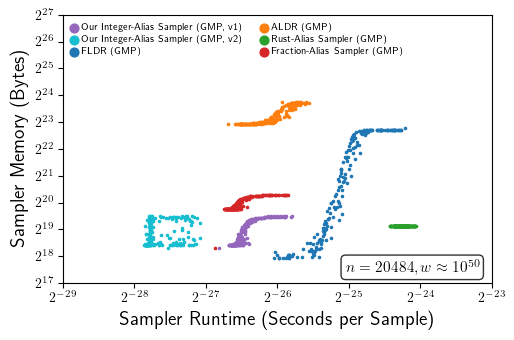

In [28]:
fig, ax, collections = run_plot_rate_size(samplers, rates, sizes)

ax.set_xlim([2**-29, 2**-23])
ax.set_ylim([2**17, 2**27])

ax.xaxis.set_major_locator(
    ticker.LogLocator(base=2., subs=(1,), numticks=7))
ax.xaxis.set_minor_locator(ticker.NullLocator())
ax.yaxis.set_major_locator(
    ticker.LogLocator(base=2., subs=(1,), numticks=11))
ax.yaxis.set_minor_locator(ticker.NullLocator())

legend_text = rf'$n={n}, w\approx10^{{{Z}}}$'
ax.text(
    0.97, 0.03, legend_text, transform=ax.transAxes,
    ha='right', va='bottom', fontsize=11,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    labels,
    loc='upper left',
    framealpha=0,
    ncol=2,
    fontsize=7,
    labelspacing=0.2,
    handletextpad=.5,
    handlelength=.5,
    markerscale=4)

fig.set_tight_layout(True)
fig.set_size_inches(5.25, 3.5)
for ext in ['pdf', 'png']:
    fig.savefig('figure-4-interpolation-opt-runtime-memory.%s' % (ext,))

#### Plot Entropy--Rate

In [29]:
from scipy.signal import savgol_filter

In [30]:
def run_plot_entropy_rate(samplers, entropies, rates):
    fig, ax = plt.subplots()

    for s in selection:
        for sampler, rate in zip(samplers, rates):
            if sampler != s:
                continue

            sc = ax.scatter([], [], label=rf'{LABELS[sampler]}', color=COLORS.get(sampler), s=10)
            color = sc.get_facecolors()[0]

            ax.scatter(entropies, rate, color=color, marker='.', s=2)

            # # Régression SANS sklearn
            # x = entropies
            # y = np.log2(rate)

            # a, b = np.polyfit(x, y, 1)

            # x_line = np.linspace(x.min(), x.max(), 200)
            # y_line = 2 ** (a * x_line + b)

            # ax.plot(x_line, y_line, linestyle='--', color=color)

            # print(f"{sampler} slope (entropy): {a:.3f}")

    ax.set_yscale('log', base=2)

    ax.set_xlabel('Entropy of Target Distribution', fontsize=11)
    ax.set_ylabel('Sampler Runtime (Seconds per Sample)', fontsize=11)

    ax.legend(loc='upper left', bbox_to_anchor=(1,1))

    fig.set_tight_layout(True)
    fig.set_size_inches((8, 6))

    return fig, ax

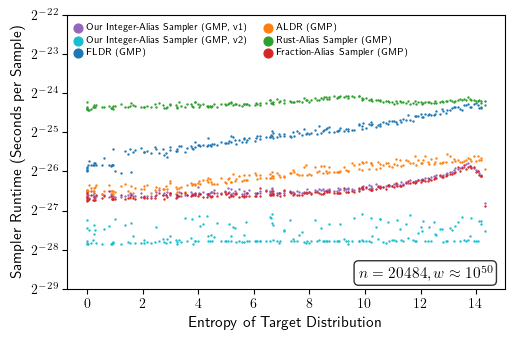

In [31]:
fig, ax = run_plot_entropy_rate(samplers, entropies, rates)

#ax.set_xlim([0, 10])
ax.set_ylim([2**-29, 2**-22])

# Add legend for N, Z, warmup status, and distribution type at top right
legend_text = rf'$n={n}, w\approx10^{{{Z}}}$'
#\nDistribution: Dirichlet (Saad)'
ax.text(0.97, 0.03, legend_text, transform=ax.transAxes, ha='right', va='bottom', fontsize=11, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

handles, labels = ax.get_legend_handles_labels()
order = list(range(len(handles)))#[6, 1, 3, 5, 0, 4, 2]
order = [i for i in order if i < len(handles)]
ax.legend(
    [handles[idx] for idx in order],
    [labels[idx] for idx in order],
    loc='upper left',
    framealpha=0,
    ncol=2,
    fontsize=7,
    labelspacing=0.3,
    handletextpad=.5,
    handlelength=.5,
    markerscale=2
)

fig.set_tight_layout(True)
fig.set_size_inches(5.25, 3.5)
for ext in ['pdf', 'png']:
    fig.savefig('figure-4-interpolation-opt-entropy-runtimes.%s' % (ext,))

#### Plot Entropy--Bits

In [32]:
def run_plot_entropy_bits(samplers, entropies, bits):
    fig, ax = plt.subplots()

    for s in selection:
        for sampler, bit in zip(samplers, bits):
            if sampler != s:
                continue

            sc = ax.scatter([], [], label=rf'{LABELS[sampler]}', color=COLORS.get(sampler), s=50)
            color = sc.get_facecolors()[0]

            ax.scatter(entropies, bit, color=color, marker='.', s=2)

            # # Régression SANS sklearn
            # x = entropies
            # #y = np.log2(bit)
            # y = bit

            # a, b = np.polyfit(x, y, 1)

            # x_line = np.linspace(x.min(), x.max(), 200)
            # #y_line = 2 ** (a * x_line + b)
            # y_line = (a * x_line + b)

            #ax.plot(x_line, y_line, linestyle='--', color=color)

            #print(f"{sampler} slope (entropy): {a:.3f}")

    ax.set_yscale('linear')

    ax.set_xlabel('Entropy of Target Distribution', fontsize=14)
    ax.set_ylabel('Average number of bits consumed', fontsize=12)

    ax.legend(loc='upper left', bbox_to_anchor=(1,1))

    fig.set_tight_layout(True)
    fig.set_size_inches((8, 6))

    return fig, ax

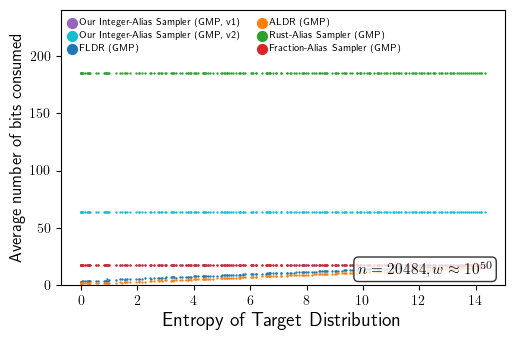

In [33]:
fig, ax = run_plot_entropy_bits(samplers, entropies, bits)

#ax.set_xlim([0, 10])
ax.set_ylim([0, 240])

# Add legend for N, Z, warmup status, and distribution type at top right
legend_text = rf'$n={n}, w\approx10^{{{Z}}}$'
#\nDistribution: Dirichlet (Saad)'
ax.text(0.97, 0.03, legend_text, transform=ax.transAxes, ha='right', va='bottom', fontsize=11, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

handles, labels = ax.get_legend_handles_labels()
order = list(range(len(handles)))#[6, 1, 3, 5, 0, 4, 2]
order = [i for i in order if i < len(handles)]
ax.legend(
    [handles[idx] for idx in order],
    [labels[idx] for idx in order],
    loc='upper left',
    framealpha=0,
    ncol=2,
    fontsize=7,
    labelspacing=0.3,
    handletextpad=.5,
    handlelength=.5,
)

fig.set_tight_layout(True)
fig.set_size_inches(5.25, 3.5)
for ext in ['pdf', 'png']:
    fig.savefig('figure-4-interpolation-opt-entropy-bits-rust.%s' % (ext,))

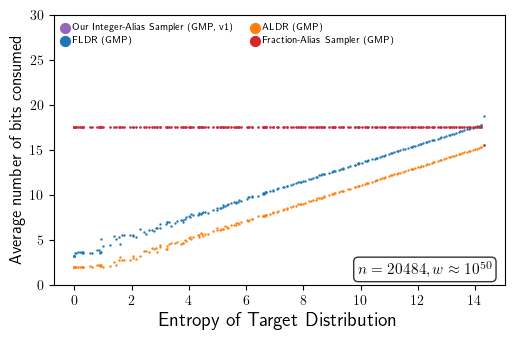

In [34]:
def run_plot_entropy_bits(samplers, entropies, bits):
    fig, ax = plt.subplots()

    for s in selection:
        for sampler, bit in zip(samplers, bits):
            if sampler != s:
                continue

            sc = ax.scatter([], [], label=rf'{LABELS[sampler]}', color=COLORS.get(sampler), s=50)
            color = sc.get_facecolors()[0]

            ax.scatter(entropies, bit, color=color, marker='.', s=2)

            # # Régression SANS sklearn
            # x = entropies
            # #y = np.log2(bit)
            # y = bit

            # a, b = np.polyfit(x, y, 1)

            # x_line = np.linspace(x.min(), x.max(), 200)
            # #y_line = 2 ** (a * x_line + b)
            # y_line = (a * x_line + b)

            # #ax.plot(x_line, y_line, linestyle='--', color=color)

            # print(f"{sampler} slope (entropy): {a:.3f}")

    ax.set_yscale('linear')

    ax.set_xlabel('Entropy of Target Distribution', fontsize=14)
    ax.set_ylabel('Average number of bits consumed', fontsize=12)

    ax.legend(loc='upper left', bbox_to_anchor=(1,1))

    fig.set_tight_layout(True)
    fig.set_size_inches((8, 6))

    return fig, ax

fig, ax = run_plot_entropy_bits(samplers, entropies, bits)

#ax.set_xlim([0, 10])
ax.set_ylim([0, 30])

# Add legend for N, Z, warmup status, and distribution type at top right
legend_text = rf'$n={n}, w\approx10^{{{Z}}}$'
#\nDistribution: Dirichlet (Saad)'
ax.text(0.97, 0.03, legend_text, transform=ax.transAxes, ha='right', va='bottom', fontsize=11, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

handles, labels = ax.get_legend_handles_labels()
order = [i for i in range(len(handles)) if 'Rust' not in labels[i] and 'v2' not in labels[i]] # Rust (~185 bits) et v2 (64 bits) hors échelle
order = [i for i in order if i < len(handles)]
ax.legend(
    [handles[idx] for idx in order],
    [labels[idx] for idx in order],
    loc='upper left',
    framealpha=0,
    ncol=2,
    fontsize=7,
    labelspacing=0.3,
    handletextpad=.5,
    handlelength=.5,
)

fig.set_tight_layout(True)
fig.set_size_inches(5.25, 3.5)
for ext in ['pdf', 'png']:
    fig.savefig('figure-4-interpolation-opt-entropy-bits.%s' % (ext,))

#### Plot Entropy--Memory

In [35]:
def run_plot_entropy_memory(samplers, entropies, sizes):
    fig, ax = plt.subplots()

    for s in selection:
        for sampler, bit in zip(samplers, sizes):
            if sampler != s:
                continue

            sc = ax.scatter([], [], label=rf'{LABELS[sampler]}', color=COLORS.get(sampler), s=50)
            color = sc.get_facecolors()[0]

            ax.scatter(entropies, bit, color=color, marker='.', s=2)

            # Régression SANS sklearn
            #x = entropies
            #y = np.log2(bit)
            # y = bit

            #a, b = np.polyfit(x, y, 1)

            #x_line = np.linspace(x.min(), x.max(), 200)
            #y_line = 2 ** (a * x_line + b)
            #y_line = (a * x_line + b)

            #ax.plot(x_line, y_line, linestyle='--', color=color)

            #print(f"{sampler} slope (entropy): {a:.3f}")

    ax.set_yscale('log', base=2)

    ax.set_xlabel('Entropy of Target Distribution', fontsize=14)
    ax.set_ylabel('Sampler Memory (Bytes)', fontsize=12)

    ax.legend(loc='upper left', bbox_to_anchor=(1,1))

    fig.set_tight_layout(True)
    fig.set_size_inches((8, 6))

    return fig, ax

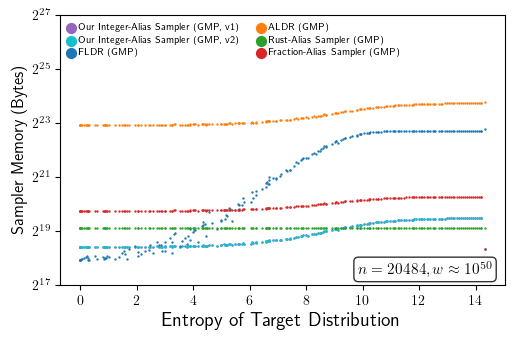

In [36]:
fig, ax = run_plot_entropy_memory(samplers, entropies, sizes)

#ax.set_xlim([0, 10])
ax.set_ylim([2**17, 2**27])

# Add legend for N, Z, warmup status, and distribution type at top right
legend_text = rf'$n={n}, w\approx10^{{{Z}}}$'
#\nDistribution: Dirichlet (Saad)'
ax.text(0.97, 0.03, legend_text, transform=ax.transAxes, ha='right', va='bottom', fontsize=11, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

handles, labels = ax.get_legend_handles_labels()
order = list(range(len(handles)))#[6, 1, 3, 5, 0, 4, 2]
order = [i for i in order if i < len(handles)]
ax.legend(
    [handles[idx] for idx in order],
    [labels[idx] for idx in order],
    loc='upper left',
    framealpha=0,
    ncol=2,
    fontsize=7,
    labelspacing=0.3,
    handletextpad=.5,
    handlelength=.5,
#     bbox_to_anchor=(1,1),
)

fig.set_tight_layout(True)
fig.set_size_inches(5.25, 3.5)
for ext in ['pdf', 'png']:
    fig.savefig('figure-4-interpolation-opt-entropy-memory.%s' % (ext,))

#### Plot Sampling Time (sec)--Bits

In [37]:
def run_plot_entropy_bits(samplers, rates, bits):
    fig, ax = plt.subplots()

    for s in selection:
        for sampler, rate, bit in zip(samplers, rates, bits):
            if sampler != s:
                continue

            sc = ax.scatter([], [], label=rf'{LABELS[sampler]}', color=COLORS.get(sampler), s=50)
            color = sc.get_facecolors()[0]

            ax.scatter(rate, bit, color=color, marker='.', s=2)

            x = rate
            y = bit

            a, b = np.polyfit(x, y, 1)

            x_line = np.linspace(x.min(), x.max(), 200)
            y_line = (a * x_line + b)

            ax.plot(x_line, y_line, linestyle='--', color=color)

            print(f"{sampler} slope (sampling time): {a:.3f}")

    ax.set_yscale('linear')

    ax.set_xlabel('Sampling Time (sec)', fontsize=14)
    ax.set_ylabel('Average number of bits consumed', fontsize=12)

    ax.legend(loc='upper left', bbox_to_anchor=(1,1))

    fig.set_tight_layout(True)
    fig.set_size_inches((8, 6))

    return fig, ax

alias.integers_opt slope (sampling time): 8623823.140
alias.integers_v2 slope (sampling time): -7853.895
rej.enc_opt slope (sampling time): 466593559.411
aldr_opt slope (sampling time): 1423842722.113
alias.rust_opt slope (sampling time): 11076.462
alias.fractions_opt slope (sampling time): 8503552.891


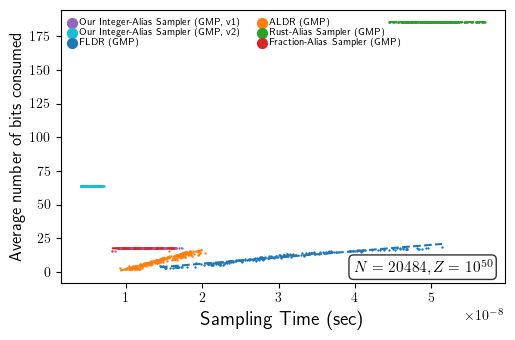

In [38]:
fig, ax = run_plot_entropy_bits(samplers, rates, bits)

#ax.set_xlim([0, 10])
#ax.set_ylim([10, 15])

# Add legend for N, Z, warmup status, and distribution type at top right
legend_text = rf'$N={n}, Z=10^{{{Z}}}$'
#\nDistribution: Dirichlet (Saad)'
ax.text(0.97, 0.03, legend_text, transform=ax.transAxes, ha='right', va='bottom', fontsize=11, bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

handles, labels = ax.get_legend_handles_labels()
order = list(range(len(handles)))#[6, 1, 3, 5, 0, 4, 2]
order = [i for i in order if i < len(handles)]
ax.legend(
    [handles[idx] for idx in order],
    [labels[idx] for idx in order],
    loc='upper left',
    framealpha=0,
    ncol=2,
    fontsize=7,
    labelspacing=0,
    handletextpad=.5,
    handlelength=.5,
#     bbox_to_anchor=(1,1),
)

fig.set_tight_layout(True)
fig.set_size_inches(5.25, 3.5)
for ext in ['pdf', 'png']:
    fig.savefig('figure-4-interpolation-opt-runtime-bits.%s' % (ext,))